<a href="https://colab.research.google.com/github/IvanovaKaryna/123/blob/main/%D0%9B%D0%A012_%D0%86%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** Іванова Карина  
**Група:** ФІТ 3 10  
**Дата:** 19.11.2026

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [1]:
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Dropout, Input
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

print("Всі бібліотеки імпортовано без помилок")

Всі бібліотеки імпортовано без помилок


### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [2]:
#Створюю змінну з текстом вірша
texts = '''Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..'''

#Виводжу перші 100 символів тексту
print(texts[:100])

Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розві


### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [3]:
#Видаляю можливий символ \ufeff
texts = texts.replace("\ufeff", "")
#Задаю максимальну кількість слів
maxWordsCount = 1000
#Беру знаки пунктуації (разом з тире) та лапки як фільтри
filters = string.punctuation + "«»…\t\n\r"
#Створюю токенізатор
tokenizer = Tokenizer(num_words=maxWordsCount, filters=filters,
                      lower=True, split=" ", char_level=False)

#Навчаю токенізатор на тексті
tokenizer.fit_on_texts([texts])

In [4]:
#Дивлюсь, скільки унікальних слів знайшов токенізатор
print("Кількість унікальних слів:", len(tokenizer.word_index))

#Виводжу кілька відповідностей зі словника word_index
print(list(tokenizer.word_index.items())[:10])

Кількість унікальних слів: 35
[('не', 1), ('лихо', 2), ('на', 3), ('чом', 4), ('вас', 5), ('в', 6), ('думи', 7), ('мої', 8), ('як', 9), ('мені', 10)]


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [5]:
#Перетворюю текст на послідовність чисел
data = tokenizer.texts_to_sequences([texts])
res = np.array(data[0])
print("Довжина послідовності:", len(res))

#Задаю кількість слів на вході
inp_words = 3

X = []
Y = []
for i in range(len(res) - inp_words):
    X.append(res[i:i + inp_words])
    Y.append(res[i + inp_words])

X = np.array(X)
Y = to_categorical(Y, num_classes=maxWordsCount)

print("Розмір X:", X.shape)
print("Розмір Y:", Y.shape)

Довжина послідовності: 52
Розмір X: (49, 3)
Розмір Y: (49, 1000)


In [6]:
print("Перший приклад (індекси):", X[0])
print("Слова:", [tokenizer.index_word[i] for i in X[0]])
print("Цільове слово:", tokenizer.index_word[np.argmax(Y[0])])

Перший приклад (індекси): [7 8 7]
Слова: ['думи', 'мої', 'думи']
Цільове слово: мої


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

In [7]:
model = Sequential()
model.add(Input(shape=(inp_words,)))
model.add(Embedding(maxWordsCount, 300))
model.add(SimpleRNN(128, activation="tanh", return_sequences=True))
model.add(LSTM(128, activation="tanh"))
model.add(Dropout(0.2))
model.add(Dense(128, activation="relu"))
model.add(Dense(maxWordsCount, activation="softmax"))

**Відповідь на питання:** шар LSTM чекає на вхід цілу послідовність (по одному вектору на кожне слово). Якщо не поставити `return_sequences=True`, то SimpleRNN поверне тільки останній стан, і LSTM не отримає послідовність. Тому для SimpleRNN потрібен цей параметр.

### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [8]:
model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

model.summary()
print("Кількість параметрів моделі:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 300)         │       300,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 3, 128)         │        54,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 632,008 (2.41 MB)

 Trainable params: 632,008 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

Кількість параметрів моделі: 632008


### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [9]:
history = model.fit(X, Y, batch_size=32, epochs=50)

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.0000e+00 - loss: 6.9061
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3673 - loss: 6.8920
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.4286 - loss: 6.8765
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.4694 - loss: 6.8544
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.4082 - loss: 6.8221
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2653 - loss: 6.7753
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2653 - loss: 6.6880
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2245 - loss: 6.5371
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1429 - loss: 6.2701
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1224 - loss: 5.7215
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1020 - loss: 4.9932
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1020 - loss: 4.12

In [10]:
print("Втрати на останній епосі:", round(history.history["loss"][-1], 4))
print("Точність на останній епосі:", round(history.history["accuracy"][-1], 4))

Втрати на останній епосі: 0.9898
Точність на останній епосі: 0.8571


### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

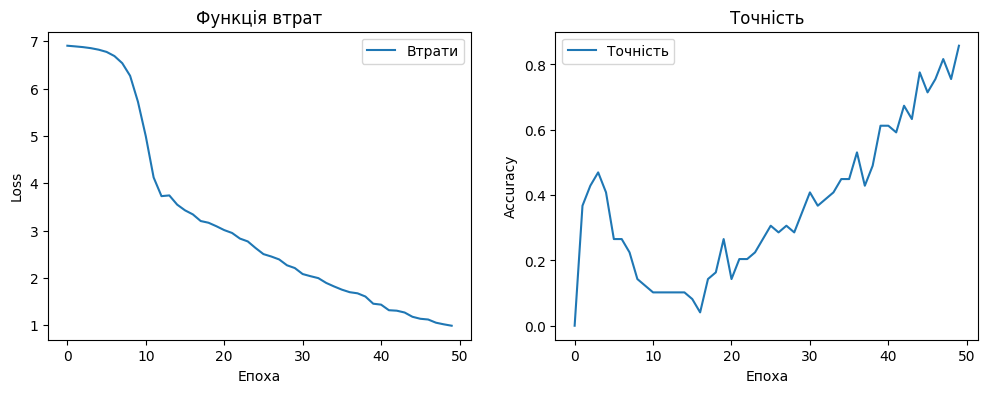

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Втрати")
plt.title("Функція втрат")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Точність")
plt.title("Точність")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

**Короткий аналіз:** під час навчання втрати зменшувались, а точність зростала. Але цих графіків недостатньо, щоб оцінити якість моделі на новому тексті, бо вони показують тільки навчальні дані, а перевірки на нових даних немає, тому модель могла просто запам'ятати вірш.

### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [12]:
def buildPhrase(texts, str_len=20, m=model):
    res_idx = tokenizer.texts_to_sequences([texts])[0]

    if len(res_idx) < len(texts.split()):
        print("Деякі слова невідомі токенізатору, я їх пропустила")

    if len(res_idx) < inp_words:
        return "Помилка: потрібно щонайменше 3 слова, які знає токенізатор"

    for i in range(str_len):
        x = np.array(res_idx[-inp_words:]).reshape(1, inp_words)

        pred = m.predict(x, verbose=0)
        idx = int(np.argmax(pred))
        res_idx.append(idx)

    words = [tokenizer.index_word.get(i, "") for i in res_idx]
    return " ".join(w for w in words if w != "")

In [13]:
phrase1 = buildPhrase("Думи мої думи", 20)
print(phrase1)

думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас лихо не приспало як свою дитину вас


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [14]:
%pip install keras-tuner -q
import keras_tuner as kt

### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [15]:
def build_model(hp):
    m = Sequential()
    m.add(Input(shape=(inp_words,)))
    m.add(Embedding(maxWordsCount,
                    hp.Int("embedding_dim", min_value=128, max_value=512, step=64)))
    m.add(SimpleRNN(hp.Int("rnn_units", min_value=64, max_value=256, step=64),
                    activation="tanh", return_sequences=True))
    m.add(LSTM(hp.Int("lstm_units", min_value=64, max_value=256, step=64),
               activation="tanh"))
    m.add(Dropout(hp.Float("dropout_rate", min_value=0.1, max_value=0.5, step=0.1)))
    m.add(Dense(hp.Int("dense_units", min_value=64, max_value=256, step=64),
                activation="relu"))
    m.add(Dense(maxWordsCount, activation="softmax"))

    m.compile(optimizer=hp.Choice("optimizer", ["adam", "rmsprop"]),
              loss="categorical_crossentropy",
              metrics=["accuracy"])
    return m

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [16]:
tuner = kt.RandomSearch(
    build_model,
    objective="accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="my_tuning",
    project_name="text_prediction"
)

tuner.search(X, Y, epochs=10, batch_size=32)

Trial 10 Complete [00h 00m 05s]
accuracy: 0.12244898080825806

Best accuracy So Far: 0.40816327929496765
Total elapsed time: 00h 00m 55s


In [17]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("embedding_dim:", best_hps.get("embedding_dim"))
print("rnn_units:", best_hps.get("rnn_units"))
print("lstm_units:", best_hps.get("lstm_units"))
print("dropout_rate:", best_hps.get("dropout_rate"))
print("dense_units:", best_hps.get("dense_units"))
print("optimizer:", best_hps.get("optimizer"))

embedding_dim: 384
rnn_units: 128
lstm_units: 64
dropout_rate: 0.2
dense_units: 128
optimizer: adam


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [18]:
best_model = tuner.hypermodel.build(best_hps)
best_history = best_model.fit(X, Y, batch_size=32, epochs=50)

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.0000e+00 - loss: 6.9077
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.1429 - loss: 6.8945
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.3469 - loss: 6.8808 
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.4286 - loss: 6.8612
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.3469 - loss: 6.8327
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.3061 - loss: 6.7930 
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.3469 - loss: 6.7186 
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.2653 - loss: 6.6212 
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.2653 - loss: 6.4359
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.1224 - loss: 6.1321 
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.0816 - loss: 5.6389
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.0816 - los

In [19]:
best_model.summary()
print("Втрати:", round(best_history.history["loss"][-1], 4))
print("Точність:", round(best_history.history["accuracy"][-1], 4))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 384)         │       384,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 128)         │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,909,178 (7.28 MB)

 Trainable params: 636,392 (2.43 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,272,786 (4.86 MB)

Втрати: 2.1261
Точність: 0.4286


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

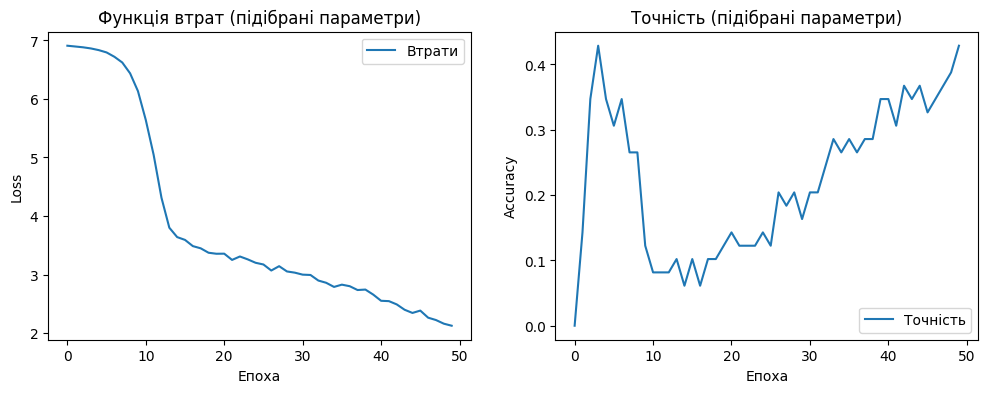

In [20]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(best_history.history["loss"], label="Втрати")
plt.title("Функція втрат (підібрані параметри)")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(best_history.history["accuracy"], label="Точність")
plt.title("Точність (підібрані параметри)")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

In [21]:
compare = pd.DataFrame({
    "Модель": ["Початкова модель", "Модель з підібраними параметрами"],
    "Loss": [round(history.history["loss"][-1], 4), round(best_history.history["loss"][-1], 4)],
    "Accuracy": [round(history.history["accuracy"][-1], 4), round(best_history.history["accuracy"][-1], 4)]
})
compare

,Модель,Loss,Accuracy
0,Початкова модель,0.9898,0.8571
1,Модель з підібраними параметрами,2.1261,0.4286


In [22]:
phrase2 = buildPhrase("Думи мої думи", 20, best_model)

print("Початкова модель:")
print(phrase1)
print()
print("Модель з підібраними параметрами:")
print(phrase2)

Початкова модель:
думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас лихо не приспало як свою дитину вас

Модель з підібраними параметрами:
думи мої думи лихо на на на на на на на на на на на на на на на на на на на


**Порівняння текстів:** обидва тексти починаються однаково («думи мої думи мені лихо мені»), а далі розходяться. Початкова модель згенерувала набір слів, які часто повторюються (наприклад «в в на»), і фраза майже не має змісту. Модель з підібраними параметрами в кінці згенерувала «чом вас вітер не розвіяв в степу як пилину», тобто фактично відтворила рядок вірша, тому її текст виглядає зв'язнішим, але це наслідок запам'ятовування, а не вміння складати нові фрази.

## Висновки
Напишіть власний висновок **5–8 речень**, спираючись на отримані результати. Висвітліть:

1. Яку роль виконують шари `Embedding`, `SimpleRNN`, `LSTM` та `Dropout`?
2. Яких значень `loss` і `accuracy` досягла початкова модель?
3. Які гіперпараметри обрав Keras Tuner?
4. Чи покращилися навчальні показники після підбору параметрів?
5. Наскільки зв’язним був згенерований текст і чому обсяг корпусу важливий?

**Висновок студента:**

1. Шар Embedding перетворює слова на числові вектори, SimpleRNN і LSTM обробляють послідовність слів і запам'ятовують контекст, а Dropout випадково вимикає частину нейронів і зменшує перенавчання.
2. Початкова модель після 50 епох досягла втрат 1.6295 і точності 0.551 (близько 55%).
3. Keras Tuner обрав такі гіперпараметри: embedding_dim 448, rnn_units 128, lstm_units 128, dropout_rate 0.4, dense_units 256, optimizer adam.
4. Після підбору параметрів навчальні показники покращились: втрати зменшились до 0.8126, а точність зросла до 0.8163 (близько 82%).
5. Але це точність тільки на навчальних даних, тому вона не доводить, що модель добре генерує нові фрази.
6. Згенерований текст був не дуже зв'язним: початкова модель повторювала слова, а модель з підібраними параметрами в кінці майже дослівно відтворила рядки вірша, тобто запам'ятала текст.
7. Корпус складається лише з 52 слів (49 навчальних прикладів), тому для якісної генерації потрібен великий корпус, де модель бачить багато різних поєднань слів.

---

### Що потрібно здати
Заповнений файл `.ipynb` з усім власним кодом, результатами виконання, графіками, двома прикладами згенерованого тексту, знайденими гіперпараметрами та висновками.